In [33]:
# Clear all variables and import libraries
%reset -f
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import glob
from scipy.interpolate import griddata
import re
import os
from math import ceil
from collections import defaultdict

In [34]:
# Configuration - Update these paths to your data folders
exp_folder = '../30/exp/Re500/pos3_transformed'
sim_folder = '../30/sim/30_Re_500/Pos3_transformed_f250'

#exp_folder = '../40/exp/40_degree_jet_00/Pos1_transformed'
#sim_folder = '../40/sim/40/Pos1_transformed'

# exp_folder = '../irregular/exp/Pos1_transformed'
# sim_folder = '../irregular/sim/irregular_0.07_extended/Pos1_transformed'

folder_name = 'Re500'  # Output folder for plots
output_dir = '../Plots/'+ folder_name

z_velocity_offset = 0.01  # Constant term to add to simulation Z-velocity [m/s]
# Define distance steps from bottom (in meters)
distance_step = 0.002  # 2 mm steps
max_distance = 0.009   # Up to 10 mm from bottom

FLIP_LAYERS = 0
TRIM_TO_COMMON_X_RANGE = 1

In [35]:
# Create output directory if it doesn't exist
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Load all CSV files
exp_files = glob.glob(f"{exp_folder}/*.csv")
sim_files = glob.glob(f"{sim_folder}/*.csv")

exp_files.sort()
sim_files.sort()
exp_files = exp_files[::-1]  # Reverse to match layer order
sim_files = sim_files[::-1]

print(f"Found {len(exp_files)} experimental files")
print(f"Found {len(sim_files)} simulation files")

# Load dataframes
exp_dataframes = [pd.read_csv(file) for file in exp_files]
sim_dataframes = [pd.read_csv(file) for file in sim_files]

# Extract file names for layer labels
exp_file_names = [os.path.basename(file) for file in exp_files]
sim_file_names = [os.path.basename(file) for file in sim_files]

print(f"\nExperimental files: {exp_file_names}")
print(f"Simulation files: {sim_file_names}")

# Auto-detect position and Reynolds number from first filename
# Try experimental files first, then simulation files
test_filename = exp_file_names[0] if len(exp_file_names) > 0 else sim_file_names[0]

# Extract position
pos_match = re.search(r'Pos(\d+)', test_filename)
if pos_match:
    position = int(pos_match.group(1))
    print(f"Automatically detected Position: {position}")
else:
    position = 1  # Default fallback
    print(f"Could not detect position from filename, using default: {position}")

# Extract Reynolds number
re_match = re.search(r'Re(\d+)', test_filename)
if re_match:
    Re_p = int(re_match.group(1))
    print(f"Automatically detected Re_p: {Re_p}")
else:
    Re_p = 100  # Default fallback
    print(f"Could not detect Re_p from filename, using default: {Re_p}")

Found 5 experimental files
Found 5 simulation files

Experimental files: ['L17_Pos03_Re0500_001_T_transformed.csv', 'L16_Pos03_Re0500_001_T_transformed.csv', 'L15_Pos03_Re0500_001_T_transformed.csv', 'L14_Pos03_Re0500_001_T_transformed.csv', 'L13_Pos03_Re0500_001_T_transformed.csv']
Simulation files: ['SIM_L17_Pos3_F250_B0001_T_transformed.csv', 'SIM_L16_Pos3_F250_B0001_T_transformed.csv', 'SIM_L15_Pos3_F250_B0001_T_transformed.csv', 'SIM_L14_Pos3_F250_B0001_T_transformed.csv', 'SIM_L13_Pos3_F250_B0001_T_transformed.csv']
Automatically detected Position: 3
Automatically detected Re_p: 500


In [36]:
# Plot parameters
n_grid = 500      # Grid resolution for contour
n_arrows = 14    # Number of arrows for streamplot

# Column name mappings
# Experimental data uses these column names
exp_x_col = 'x'
exp_z_col = 'z'
exp_u_col = 'Vel_u'
exp_w_col = 'Vel_w'

# Simulation data uses these column names
sim_x_col = 'Points_0'
sim_z_col = 'Points_2'
sim_u_col = 'av_u_0'
sim_w_col = 'av_u_2'

# sim_x_col = 'x'
# sim_z_col = 'z'
#sim_u_col = 'Vel_u_transformed'
#sim_w_col = 'Vel_w_transformed'

print(f"Grid resolution: {n_grid}")
print(f"Streamplot arrows: {n_arrows}")

# Apply z_velocity_offset to simulation data and calculate velocity magnitudes
print("Applying z_velocity_offset to simulation data...")
for df_sim in sim_dataframes:
    df_sim[sim_w_col] = df_sim[sim_w_col] + z_velocity_offset

print("Calculating velocity magnitudes...")

all_vel_mag_values = []

# Calculate for experimental data
for df_exp in exp_dataframes:
    df_exp['vel_magnitude'] = np.sqrt(df_exp[exp_u_col]**2 + df_exp[exp_w_col]**2)
    all_vel_mag_values.extend(df_exp['vel_magnitude'].values)

# Calculate for simulation data (with offset already applied)
for df_sim in sim_dataframes:
    df_sim['vel_magnitude'] = np.sqrt(df_sim[sim_u_col]**2 + df_sim[sim_w_col]**2)
    all_vel_mag_values.extend(df_sim['vel_magnitude'].values)

# Calculate common colorbar limits from all data
all_vel_mag_values = np.array(all_vel_mag_values)
all_vel_mag_values = all_vel_mag_values[np.isfinite(all_vel_mag_values)]  # Remove NaN and inf

common_vmin = all_vel_mag_values.min()
common_vmax = all_vel_mag_values.max()

print(f"\nCalculated velocity magnitude range from all data:")
print(f"  Min: {common_vmin:.6f} m/s")
print(f"  Max: {common_vmax:.6f} m/s")

levels = np.linspace(common_vmin, common_vmax, 50)

####
# Line plots at specific vertical distances (Z-heights)
# Show all simulation layers + middle experimental layer with std deviation

# Determine z-range for line plots (use experimental data range)
z_min_exp = float(min(df[exp_z_col].min() for df in exp_dataframes))
z_max_exp = float(max(df[exp_z_col].max() for df in exp_dataframes))

Grid resolution: 500
Streamplot arrows: 14
Applying z_velocity_offset to simulation data...
Calculating velocity magnitudes...

Calculated velocity magnitude range from all data:
  Min: 0.000000 m/s
  Max: 3.529131 m/s


In [37]:
# FLIP LAYERS 12-17 ALONG X-AXIS
# ============================================================
# Set to True to enable flipping, False to disable

if FLIP_LAYERS:
    print("\n" + "=" * 80)
    print("FLIPPING LAYERS 15-17 ALONG X-AXIS")
    print("=" * 80)
    
    layers_to_flip = ['L12', 'L13', 'L15', 'L14', 'L16', 'L17']
    flipped_exp = []
    flipped_sim = []
    
    # # Flip EXPERIMENTAL layers
    # for i, (df, filename) in enumerate(zip(exp_dataframes, exp_file_names)):
    #     # Check if this is a layer to flip
    #     layer_match = re.search(r'L(\d{2})', filename)
    #     if layer_match:
    #         layer_id = f"L{layer_match.group(1)}"
    #         if layer_id in layers_to_flip:
    #             # Store original ranges
    #             x_min_before = df[exp_x_col].min()
    #             x_max_before = df[exp_x_col].max()
    #             u_min_before = df[exp_u_col].min()
    #             u_max_before = df[exp_u_col].max()
                
    #             # Flip x-coordinate
    #             df[exp_x_col] = -df[exp_x_col]
    #             # Flip x-velocity component
    #             df[exp_u_col] = -df[exp_u_col]
                
    #             # Recalculate velocity magnitude
    #             df['vel_magnitude'] = np.sqrt(df[exp_u_col]**2 + df[exp_w_col]**2)
                
    #             # Print confirmation with ranges
    #             x_min_after = df[exp_x_col].min()
    #             x_max_after = df[exp_x_col].max()
                
    #             print(f"✓ Flipped EXPERIMENTAL {layer_id}")
    #             print(f"  X range: [{x_min_before:.6f}, {x_max_before:.6f}] → [{x_min_after:.6f}, {x_max_after:.6f}]")
    #             print(f"  Vel_u range: [{u_min_before:.6f}, {u_max_before:.6f}] → [{-u_max_before:.6f}, {-u_min_before:.6f}]")
    #             flipped_exp.append(layer_id)
    
    # Flip SIMULATION layers
    for i, (df, filename) in enumerate(zip(sim_dataframes, sim_file_names)):
        # Check if this is a layer to flip
        layer_match = re.search(r'L(\d{2})', filename)
        if layer_match:
            layer_id = f"L{layer_match.group(1)}"
            if layer_id in layers_to_flip:
                # Store original ranges
                x_min_before = df[sim_x_col].min()
                x_max_before = df[sim_x_col].max()
                u_min_before = df[sim_u_col].min()
                u_max_before = df[sim_u_col].max()
                
                # Flip x-coordinate
                df[sim_x_col] = -df[sim_x_col]
                # Flip x-velocity component
                df[sim_u_col] = -df[sim_u_col]
                
                # Recalculate velocity magnitude
                df['vel_magnitude'] = np.sqrt(df[sim_u_col]**2 + df[sim_w_col]**2)
                
                # Print confirmation with ranges
                x_min_after = df[sim_x_col].min()
                x_max_after = df[sim_x_col].max()
                
                print(f"✓ Flipped SIMULATION {layer_id}")
                print(f"  X range: [{x_min_before:.6f}, {x_max_before:.6f}] → [{x_min_after:.6f}, {x_max_after:.6f}]")
                print(f"  Vel_u range: [{u_min_before:.6f}, {u_max_before:.6f}] → [{-u_max_before:.6f}, {-u_min_before:.6f}]")
                flipped_sim.append(layer_id)
    
    print("\n" + "=" * 80)
    print(f"Flipping complete! Flipped {len(flipped_exp)} experimental + {len(flipped_sim)} simulation layers")
    print(f"Flipped layers: {', '.join(sorted(set(flipped_exp + flipped_sim)))}")
    print("=" * 80 + "\n")
else:
    print("\n" + "-" * 80)
    print("Layer flipping is DISABLED")
    print("Set FLIP_LAYERS = True to enable flipping of layers L15, L16, L17")
    print("-" * 80 + "\n")


--------------------------------------------------------------------------------
Layer flipping is DISABLED
Set FLIP_LAYERS = True to enable flipping of layers L15, L16, L17
--------------------------------------------------------------------------------



In [38]:
# TRIM DATA TO COMMON X-AXIS RANGE
# ============================================================
# This ensures all layers use the same x-axis range for better comparison

if TRIM_TO_COMMON_X_RANGE:
    print("\n" + "=" * 80)
    print("TRIMMING DATA TO COMMON X-AXIS RANGE")
    print("=" * 80)
    
    # Find the common x-range (intersection of all layers)
    # This is the range where ALL layers have data
    
    # Find max of all minimums (most restrictive lower bound)
    x_min_common = max(
        max(df[exp_x_col].min() for df in exp_dataframes),
        max(df[sim_x_col].min() for df in sim_dataframes)
    )
    
    # Find min of all maximums (most restrictive upper bound)
    x_max_common = min(
        min(df[exp_x_col].max() for df in exp_dataframes),
        min(df[sim_x_col].max() for df in sim_dataframes)
    )
    
    print(f"\nCommon X-axis range: [{x_min_common:.6f}, {x_max_common:.6f}] m")
    print(f"Range width: {(x_max_common - x_min_common)*1000:.2f} mm\n")
    
    # Trim EXPERIMENTAL layers
    trimmed_exp_counts = []
    for i, (df, filename) in enumerate(zip(exp_dataframes, exp_file_names)):
        original_count = len(df)
        
        # Filter to common x-range
        mask = (df[exp_x_col] >= x_min_common) & (df[exp_x_col] <= x_max_common)
        df_trimmed = df[mask].copy()
        
        # Replace the dataframe in the list
        exp_dataframes[i] = df_trimmed
        
        trimmed_count = original_count - len(df_trimmed)
        trimmed_exp_counts.append(trimmed_count)
        
        # Extract layer info
        layer_match = re.search(r'L(\d{2})', filename)
        layer_id = f"L{layer_match.group(1)}" if layer_match else f"Layer {i+1}"
        
        print(f"EXP {layer_id}: {original_count} → {len(df_trimmed)} points (removed {trimmed_count})")
    
    print()
    
    # Trim SIMULATION layers
    trimmed_sim_counts = []
    for i, (df, filename) in enumerate(zip(sim_dataframes, sim_file_names)):
        original_count = len(df)
        
        # Filter to common x-range
        mask = (df[sim_x_col] >= x_min_common) & (df[sim_x_col] <= x_max_common)
        df_trimmed = df[mask].copy()
        
        # Replace the dataframe in the list
        sim_dataframes[i] = df_trimmed
        
        trimmed_count = original_count - len(df_trimmed)
        trimmed_sim_counts.append(trimmed_count)
        
        # Extract layer info
        layer_match = re.search(r'L(\d{2})', filename)
        layer_id = f"L{layer_match.group(1)}" if layer_match else f"Layer {i+1}"
        
        print(f"SIM {layer_id}: {original_count} → {len(df_trimmed)} points (removed {trimmed_count})")
    
    total_trimmed = sum(trimmed_exp_counts) + sum(trimmed_sim_counts)
    
    print("\n" + "=" * 80)
    print(f"Trimming complete! Removed {total_trimmed} total points")
    print(f"All layers now span X ∈ [{x_min_common:.6f}, {x_max_common:.6f}] m")
    print("=" * 80 + "\n")
    
else:
    print("\n" + "-" * 80)
    print("X-axis trimming is DISABLED")
    print("Set TRIM_TO_COMMON_X_RANGE = True to trim all layers to common X range")
    print("-" * 80 + "\n")


TRIMMING DATA TO COMMON X-AXIS RANGE

Common X-axis range: [-0.029788, 0.029772] m
Range width: 59.56 mm

EXP L17: 6386 → 6324 points (removed 62)
EXP L16: 6592 → 6528 points (removed 64)
EXP L15: 6417 → 6355 points (removed 62)
EXP L14: 6417 → 6355 points (removed 62)
EXP L13: 6355 → 6355 points (removed 0)

SIM L17: 9144 → 9074 points (removed 70)
SIM L16: 9144 → 9074 points (removed 70)
SIM L15: 6924 → 6852 points (removed 72)
SIM L14: 9144 → 9074 points (removed 70)
SIM L13: 9144 → 9074 points (removed 70)

Trimming complete! Removed 602 total points
All layers now span X ∈ [-0.029788, 0.029772] m



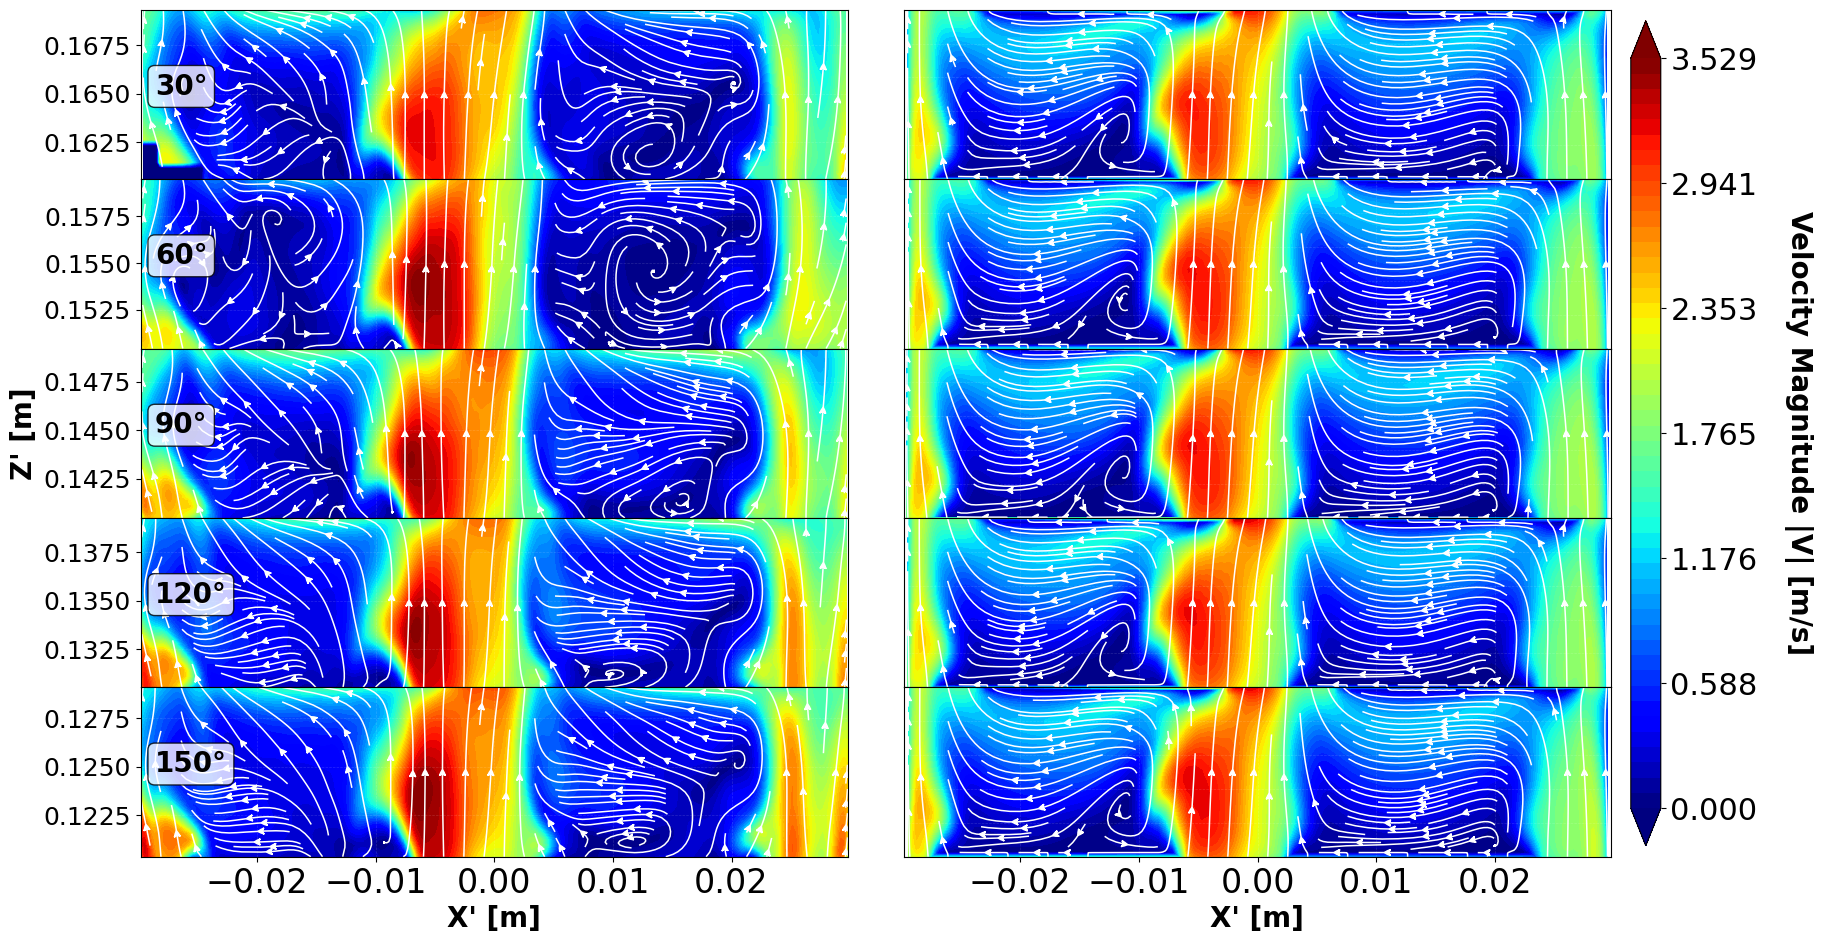

In [39]:
# Combined Exp–Sim comparison plot
# ============================================================
n_layers = min(len(exp_dataframes), len(sim_dataframes))
fig, axes = plt.subplots(
    nrows=n_layers,
    ncols=2,
    figsize=(20, 2.2 * n_layers)   # ← wider figure
)

if n_layers == 1:
    axes = axes.reshape(1, -1)

# --- Global X-limits for alignment ---
x_min_global = min(df[exp_x_col].min() for df in exp_dataframes)
x_max_global = max(df[exp_x_col].max() for df in exp_dataframes)

# --- Shared color scale already defined: common_vmin, common_vmax ---

for i in range(n_layers):
    df_exp = exp_dataframes[i]
    df_sim = sim_dataframes[i]

    # ----- Layer label -----
    try:
        angle_deg = -np.degrees(df_exp['alpha'].iloc[0])
        layer_label = f"{angle_deg:.0f}°"
    except:
        # Fallback: extract layer id from filename (e.g. L17)
        fname = exp_file_names[i] if i < len(exp_file_names) else (sim_file_names[i] if i < len(sim_file_names) else None)
        layer_match = re.search(r'L(\d+)', fname) if fname else None
        layer_label = f"L{layer_match.group(1)}" if layer_match else f"Layer {i+1}"

    # ============================================================
    # ========== EXPERIMENT (LEFT COLUMN)
    # ============================================================
    ax_exp = axes[i, 0]

    x_exp = df_exp[exp_x_col].values
    z_exp = df_exp[exp_z_col].values
    u_exp = df_exp[exp_u_col].values
    w_exp = df_exp[exp_w_col].values
    vel_mag_exp = df_exp['vel_magnitude'].values

    xi = np.linspace(x_exp.min(), x_exp.max(), n_grid)
    zi = np.linspace(z_exp.min(), z_exp.max(), n_grid)
    Xi, Zi = np.meshgrid(xi, zi)

    points = np.column_stack((x_exp, z_exp))
    Ui = griddata(points, u_exp, (Xi, Zi), method='linear', fill_value=0)
    Wi = griddata(points, w_exp, (Xi, Zi), method='linear', fill_value=0)
    Vmag = griddata(points, vel_mag_exp, (Xi, Zi), method='linear', fill_value=0)

    mag = np.sqrt(Ui**2 + Wi**2)
    Ui_norm = np.zeros_like(Ui)
    Wi_norm = np.zeros_like(Wi)
    mask = mag > 1e-6
    Ui_norm[mask] = Ui[mask]/mag[mask]
    Wi_norm[mask] = Wi[mask]/mag[mask]

    contour_exp = ax_exp.contourf(
        Xi, Zi, Vmag,
        levels=levels, cmap='jet',
        vmin=common_vmin, vmax=common_vmax, extend='both'
    )
    ax_exp.streamplot(
        Xi, Zi, Ui_norm, Wi_norm,
        density=1.2, color='white',
        linewidth=1.1, arrowsize=1.0, arrowstyle='fancy'
    )

    # --- LOCAL Z-limits: each row shows only its slice ---
    ax_exp.set_ylim(z_exp.min(), z_exp.max())
    ax_exp.set_xlim(x_min_global, x_max_global)
    ax_exp.margins(y=0)

    ax_exp.grid(True, linestyle='--', alpha=0.15, color='white', linewidth=0.5)
    ax_exp.tick_params(axis='x', bottom=False, labelbottom=False)
    ax_exp.tick_params(axis='y', left=True, labelleft=True, labelsize=18)

    # ----- Row label -----
    ax_exp.annotate(
        layer_label, xy=(0.02, 0.50), xycoords='axes fraction',
        fontsize=20, fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", alpha=0.8)
    )

    # ============================================================
    # ========== SIMULATION (RIGHT COLUMN)
    # ============================================================
    ax_sim = axes[i, 1]

    x_sim = df_sim[sim_x_col].values
    z_sim = df_sim[sim_z_col].values
    u_sim = df_sim[sim_u_col].values
    w_sim = df_sim[sim_w_col].values
    vel_mag_sim = df_sim['vel_magnitude'].values

    xi = np.linspace(x_sim.min(), x_sim.max(), n_grid)
    zi = np.linspace(z_sim.min(), z_sim.max(), n_grid)
    Xi, Zi = np.meshgrid(xi, zi)

    points = np.column_stack((x_sim, z_sim))
    Ui = griddata(points, u_sim, (Xi, Zi), method='linear', fill_value=0)
    Wi = griddata(points, w_sim - z_velocity_offset, (Xi, Zi), method='linear', fill_value=0)
    Vmag = griddata(points, vel_mag_sim, (Xi, Zi), method='linear', fill_value=0)

    mag = np.sqrt(Ui**2 + Wi**2)
    Ui_norm = np.zeros_like(Ui)
    Wi_norm = np.zeros_like(Wi)
    mask = mag > 1e-6
    Ui_norm[mask] = Ui[mask]/mag[mask]
    Wi_norm[mask] = Wi[mask]/mag[mask]

    contour_sim = ax_sim.contourf(
        Xi, Zi, Vmag,
        levels=levels, cmap='jet',
        vmin=common_vmin, vmax=common_vmax, extend='both'
    )
    ax_sim.streamplot(
        Xi, Zi, Ui_norm, Wi_norm,
        density=1.2, color='white',
        linewidth=1.1, arrowsize=1.0, arrowstyle='fancy'
    )

    # --- LOCAL Z-limits ---
    ax_sim.set_ylim(z_sim.min(), z_sim.max())
    ax_sim.set_xlim(x_min_global, x_max_global)
    ax_sim.margins(y=0)

    ax_sim.grid(True, linestyle='--', alpha=0.15, color='white', linewidth=0.5)
    ax_sim.tick_params(axis='x', bottom=False, labelbottom=False)
    ax_sim.tick_params(axis='y', left=False, labelleft=False)

    # # --- Column labels in boxed style ---
    # if i == 0:
    #     ax_exp.text(
    #         0.5, 1.02, "Experiment", transform=ax_exp.transAxes,
    #         ha='center', va='bottom',
    #         fontsize=18, fontweight='bold',
    #         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.85)
    #     )

    #     ax_sim.text(
    #         0.5, 1.02, "Simulation", transform=ax_sim.transAxes,
    #         ha='center', va='bottom',
    #         fontsize=18, fontweight='bold',
    #         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.85)
    #     )

# ----- Bottom X labels -----
axes[-1, 0].tick_params(axis='x', bottom=True, labelbottom=True, labelsize=24)
axes[-1, 1].tick_params(axis='x', bottom=True, labelbottom=True, labelsize=24)
axes[-1, 0].set_xlabel("X' [m]", fontsize=20, fontweight='bold')
axes[-1, 1].set_xlabel("X' [m]", fontsize=20, fontweight='bold')

# ----- Middle Y label -----
mid = n_layers // 2
axes[mid, 0].set_ylabel("Z' [m]", fontsize=20, fontweight='bold')
# ----- Layout: no vertical gaps -----
fig.subplots_adjust(
    right=0.86,
    hspace=0.0,
    wspace=0.08   # ← small gap between columns
)

# ----- Colorbar -----
cbar_ax = fig.add_axes([0.87, 0.12, 0.015, 0.75])
cbar = fig.colorbar(contour_exp, cax=cbar_ax)
cbar.set_label('Velocity Magnitude |V| [m/s]', rotation=270, labelpad=40, fontsize=20, fontweight='bold')

from matplotlib.ticker import FormatStrFormatter
cbar.ax.tick_params(labelsize=22)
vmin, vmax = contour_exp.get_clim()
cbar.set_ticks(np.linspace(vmin, vmax, 7))
cbar.formatter = FormatStrFormatter('%.3f')
cbar.update_ticks()  # Refresh the tick labels

# ----- Title -----
# fig.suptitle(
#     f'Experiment vs Simulation Comparison - Re$_p$ = {Re_p}, Position {position}',
#     fontsize=30, fontweight='bold', y=0.985   # lower title → no extra gap
#)

plt.savefig(f'{output_dir}/Combined_Exp_Sim_Pos{position}_Re{Re_p}.png',
            dpi=300, bbox_inches='tight')

plt.show()


Plotting at distances from bottom (mm): [2.0, 4.0, 6.0, 8.0]
Total number of plots: 4

Saved: ../Plots/Re500/Line_Profiles_from_Bottom_Pos3_Re500.png


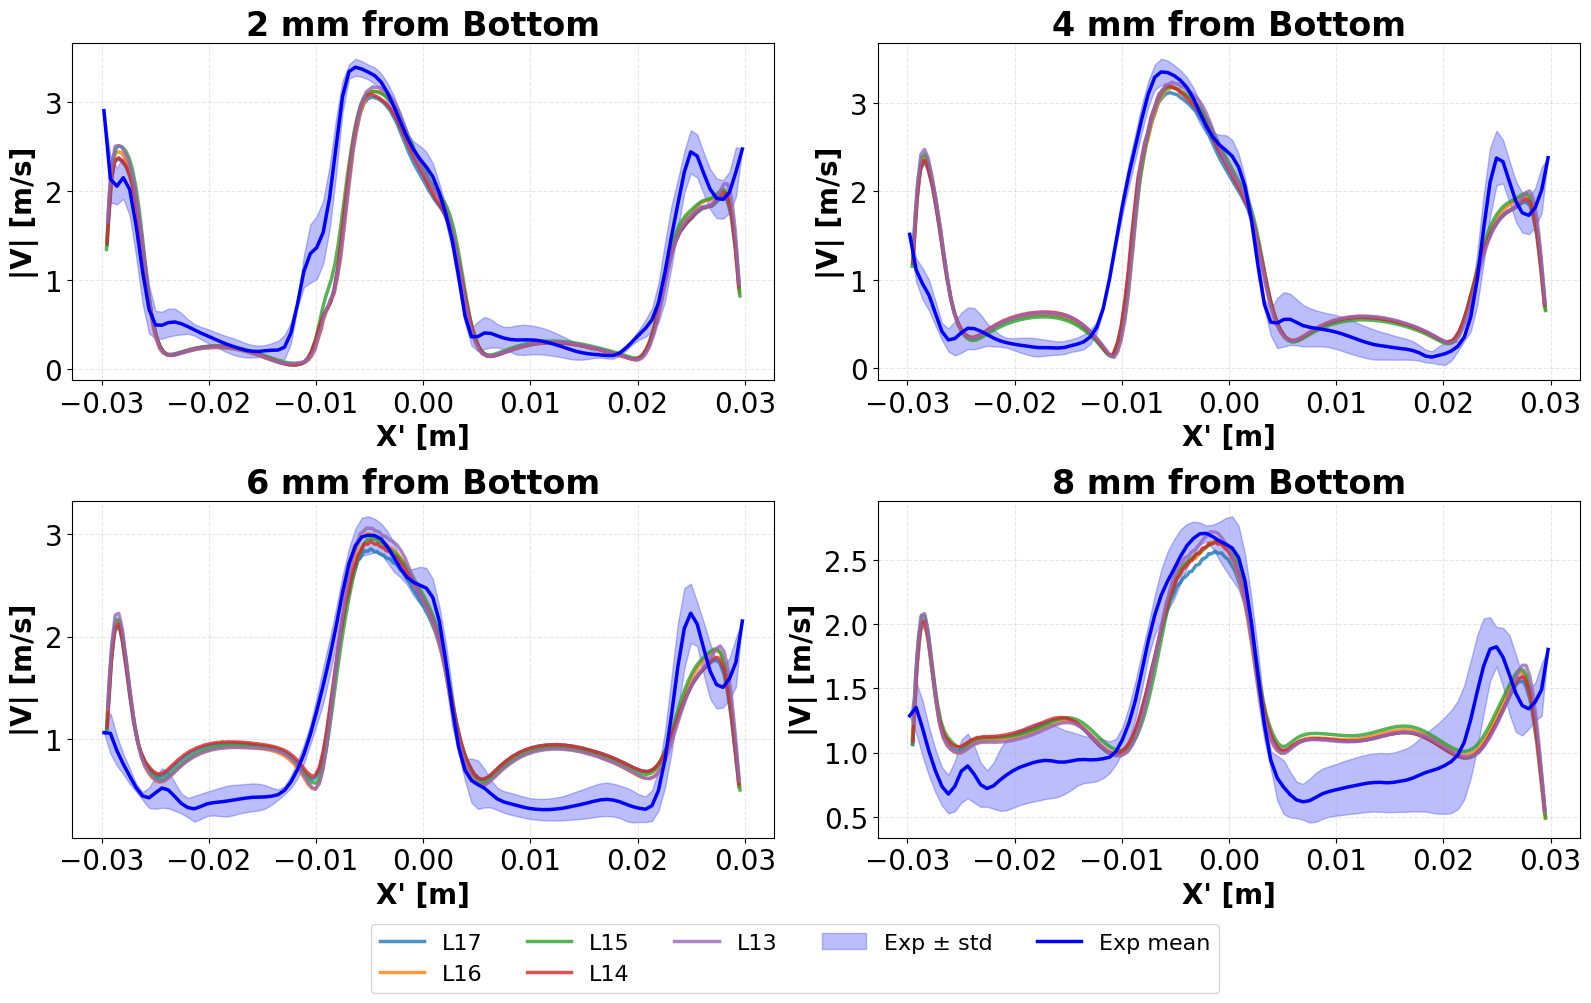

In [40]:
# Line plots at specific distances from bottom of layer
# Show all simulation layers + experimental mean with std deviation

distances_from_bottom = np.arange(distance_step, max_distance + 1e-12, distance_step)

print(f"\nPlotting at distances from bottom (mm): {[d*1000 for d in distances_from_bottom]}")
print(f"Total number of plots: {len(distances_from_bottom)}")

# Determine subplot layout
n_plots = len(distances_from_bottom)
if n_plots <= 4:
    n_rows, n_cols = 2, 2
elif n_plots <= 6:
    n_rows, n_cols = 2, 3
elif n_plots <= 9:
    n_rows, n_cols = 3, 3
else:
    n_rows, n_cols = 3, 4

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8*n_cols,5*n_rows))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

# Process each distance from bottom
for idx, distance in enumerate(distances_from_bottom):
    deci = 5  # Precision for filtering
    ax = axes[idx]
    
    # Plot all SIMULATION layers
    for i, df_sim in enumerate(sim_dataframes):
        # Calculate z-position for this layer (distance from its bottom)
        z_min_layer = df_sim[sim_z_col].min()
        z_target = z_min_layer + distance
        
        # Check if this distance exists in this layer
        if z_target <= df_sim[sim_z_col].max():
            # Find closest z-value in simulation data
            closest_z_sim = df_sim[sim_z_col].iloc[(df_sim[sim_z_col] - z_target).abs().argsort()[:1]].iloc[0]
            
            # Filter data at this Z-height
            df_sim_filtered = df_sim[abs(df_sim[sim_z_col] - closest_z_sim) < 10**(-deci)]
            
            if len(df_sim_filtered) > 0:
                df_sim_filtered = df_sim_filtered.sort_values(sim_x_col)
                
                # Extract layer label from filename
                sim_match = re.search(r'L(\d{2})', sim_file_names[i])
                layer_label = f"L{sim_match.group(1)}" if sim_match else f"Layer {i+1}"
                
                # Plot simulation layer with updated style
                ax.plot(df_sim_filtered[sim_x_col], df_sim_filtered['vel_magnitude'], 
                       label=layer_label, linestyle='-', linewidth=2.5, alpha=0.8, zorder=2)
    
    # Calculate EXPERIMENTAL data statistics across all layers
    # Collect data from all experimental layers at this distance from bottom
    all_exp_data = []
    
    for i, df_exp in enumerate(exp_dataframes):
        # Calculate z-position for this layer (distance from its bottom)
        z_min_layer = df_exp[exp_z_col].min()
        z_target = z_min_layer + distance
        
        # Check if this distance exists in this layer
        if z_target <= df_exp[exp_z_col].max():
            # Find closest z-value in experimental data
            closest_z_exp = df_exp[exp_z_col].iloc[(df_exp[exp_z_col] - z_target).abs().argsort()[:1]].iloc[0]
            
            # Filter data at this Z-height
            df_exp_filtered = df_exp[abs(df_exp[exp_z_col] - closest_z_exp) < 10**(-deci)]
            
            if len(df_exp_filtered) > 0:
                df_exp_filtered = df_exp_filtered.sort_values(exp_x_col)
                all_exp_data.append(df_exp_filtered)
    
    # Calculate mean and std across all experimental layers
    if len(all_exp_data) > 0:
        # Get common x-range from all experimental data
        x_min_all = min([df[exp_x_col].min() for df in all_exp_data])
        x_max_all = max([df[exp_x_col].max() for df in all_exp_data])
        x_grid = np.linspace(x_min_all, x_max_all, 100)
        
        vel_matrix = []
        
        for df_exp_layer in all_exp_data:
            x_layer = df_exp_layer[exp_x_col].values
            vel_layer = df_exp_layer['vel_magnitude'].values
            
            # Interpolate to common grid
            from scipy.interpolate import interp1d
            if len(x_layer) > 1:
                f_interp = interp1d(x_layer, vel_layer, kind='linear', 
                                   bounds_error=False, fill_value=np.nan)
                vel_interp = f_interp(x_grid)
                vel_matrix.append(vel_interp)
        
        # Calculate mean and std across layers
        if len(vel_matrix) > 0:
            vel_matrix = np.array(vel_matrix)
            vel_mean = np.nanmean(vel_matrix, axis=0)
            vel_std = np.nanstd(vel_matrix, axis=0)
            
            # Plot experimental mean with std deviation - updated style
            ax.fill_between(x_grid, vel_mean - vel_std, vel_mean + vel_std,
                            color='#1e28f2', alpha=0.3, label='Exp ± std', zorder=1)
            ax.plot(x_grid, vel_mean, 'b-', label='Exp mean', 
                   linewidth=2.5, zorder=3)
    
    # Configure subplot with updated font sizes
    if len(all_exp_data) > 0 or len(df_sim_filtered) > 0:
        ax.set_xlabel("X' [m]", fontsize=20, fontweight='bold')
    if len(all_exp_data) > 0 or len(df_sim_filtered) > 0:
        ax.set_ylabel('|V| [m/s]', fontsize=20, fontweight='bold')
    ax.set_title(f'{distance*1000:.0f} mm from Bottom', fontsize=24, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.tick_params(axis='x', which='both', labelsize=20)
    ax.tick_params(axis='y', which='both', labelsize=20)

# Hide unused subplots
for i in range(n_plots, len(axes)):
    axes[i].set_visible(False)

# Create single legend at the bottom for all subplots
# Get handles and labels from the first subplot (they're all the same)
handles, labels = axes[0].get_legend_handles_labels()

# Place legend below all subplots in a single row
ncol = ceil(len(labels) / 1)
# Add overall title
#fig.suptitle(f'Velocity Profiles at Different Distances \nfrom Bottom (Re$_p$ = {Re_p}, Position {position})', 
#            fontsize=18, fontweight='bold', y=0.98)

fig.legend(
    handles, labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=min(5, len(labels)),
    fontsize=16,
    frameon=True
)
# Adjust layout
fig.subplots_adjust(bottom=0.12)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])

# Save plot
plot_filename = f'{output_dir}/Line_Profiles_from_Bottom_Pos{position}_Re{Re_p}.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"\nSaved: {plot_filename}")

plt.show()

In [41]:
comparison_distance = 0.002


Plotting at 2.0 mm from bottom of each layer

Saved: ../Plots/Re500/Layer_Comparison_2mm_Pos3_Re500.png


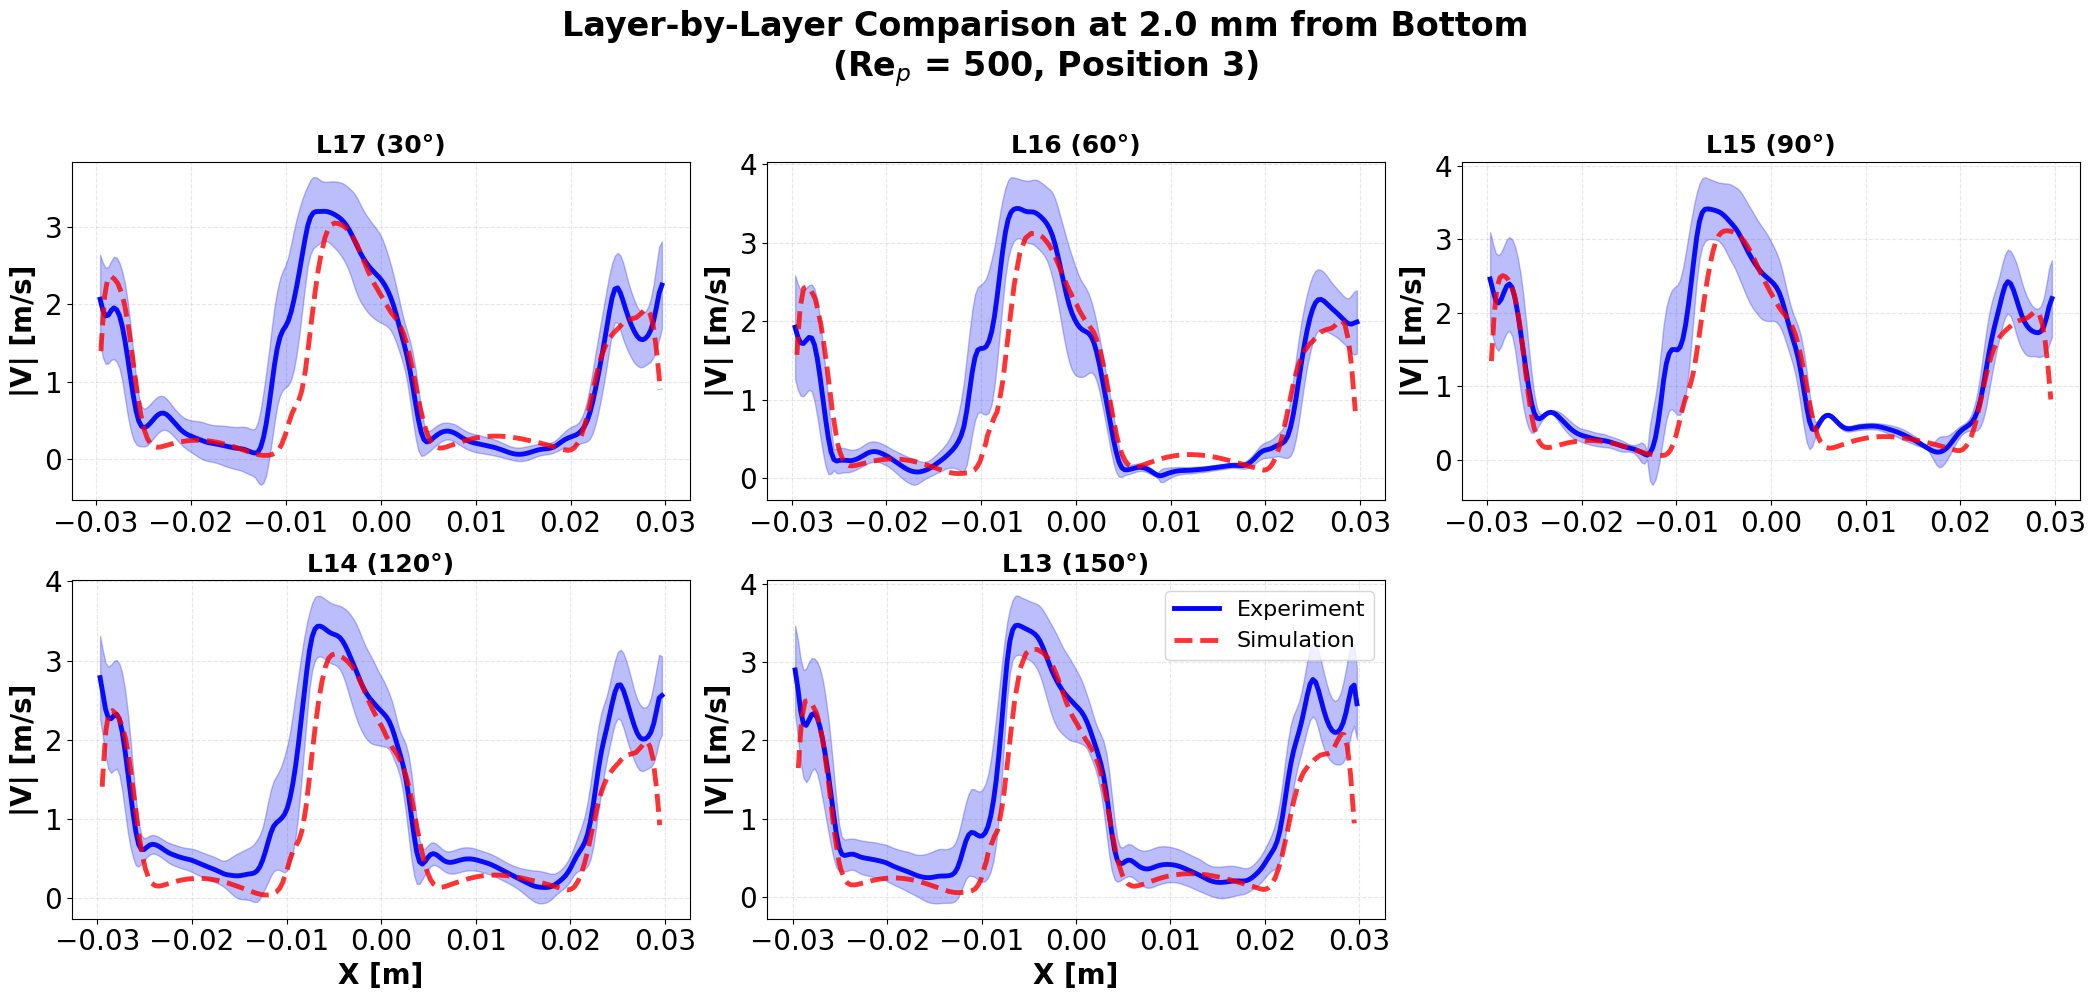

In [42]:
# Individual Layer Comparison at Specific Distance from Bottom
# Show each layer separately with Exp vs Sim line plots
# Configuration: distance from bottom to plot (in meters)

print(f"\nPlotting at {comparison_distance*1000:.1f} mm from bottom of each layer")

n_layers = min(len(exp_dataframes), len(sim_dataframes))

# Determine subplot layout
if n_layers <= 4:
    n_rows, n_cols = 2, 2
elif n_layers <= 6:
    n_rows, n_cols = 2, 3
elif n_layers <= 9:
    n_rows, n_cols = 3, 3
else:
    n_rows, n_cols = 4, 3

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7*n_cols, 5*n_rows))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

deci = 5  # Precision for filtering

# Process each layer
for i in range(n_layers):
    df_exp = exp_dataframes[i]
    df_sim = sim_dataframes[i]
    ax = axes[i]
    
    # Extract layer label
    exp_match = re.search(r'L(\d{2})', exp_file_names[i])
    layer_name = f"L{exp_match.group(1)}" if exp_match else f"Layer {i+1}"
    
    # Try to get angle from alpha column
    try:
        angle_deg = -np.degrees(df_exp['alpha'].iloc[0])
        layer_label = f"{layer_name} ({angle_deg:.0f}°)"
    except:
        layer_label = layer_name
    
    # Calculate z-position for experimental layer (distance from its bottom)
    z_min_exp = df_exp[exp_z_col].min()
    z_target_exp = z_min_exp + comparison_distance
    
    # Calculate z-position for simulation layer (distance from its bottom)
    z_min_sim = df_sim[sim_z_col].min()
    z_target_sim = z_min_sim + comparison_distance
    
    # Check if this distance exists in both layers
    exp_data_exists = z_target_exp <= df_exp[exp_z_col].max()
    sim_data_exists = z_target_sim <= df_sim[sim_z_col].max()
    
    if exp_data_exists and sim_data_exists:
        # EXPERIMENTAL DATA
        # Find closest z-value in experimental data
        closest_z_exp = df_exp[exp_z_col].iloc[(df_exp[exp_z_col] - z_target_exp).abs().argsort()[:1]].iloc[0]
        
        # Filter data at this Z-height
        df_exp_filtered = df_exp[abs(df_exp[exp_z_col] - closest_z_exp) < 10**(-deci)]
        
        if len(df_exp_filtered) > 0:
            df_exp_filtered = df_exp_filtered.sort_values(exp_x_col)
            
            # Plot experimental data with updated style
            ax.plot(df_exp_filtered[exp_x_col], df_exp_filtered['vel_magnitude'], 
                   label='Experiment', color='b', linestyle='-', linewidth=3.5, zorder=2)
            
            # Add error bars if standard deviation columns exist
            if 'Stand_dev_Vx' in df_exp_filtered.columns and 'Stand_dev_Vz' in df_exp_filtered.columns:
                std_u = df_exp_filtered['Stand_dev_Vx'].values
                std_w = df_exp_filtered['Stand_dev_Vz'].values
                
                u_vals = df_exp_filtered[exp_u_col].values
                w_vals = df_exp_filtered[exp_w_col].values
                magnitude_vals = df_exp_filtered['vel_magnitude'].values
                magnitude_vals[magnitude_vals < 1e-10] = 1e-10
                
                std_magnitude = np.sqrt((u_vals * std_u)**2 + (w_vals * std_w)**2) / magnitude_vals
                
                ax.fill_between(df_exp_filtered[exp_x_col],
                               df_exp_filtered['vel_magnitude'] - std_magnitude,
                               df_exp_filtered['vel_magnitude'] + std_magnitude,
                               color='#1e28f2', alpha=0.3, zorder=3)
        
        # SIMULATION DATA
        # Find closest z-value in simulation data
        closest_z_sim = df_sim[sim_z_col].iloc[(df_sim[sim_z_col] - z_target_sim).abs().argsort()[:1]].iloc[0]
        
        # Filter data at this Z-height
        df_sim_filtered = df_sim[abs(df_sim[sim_z_col] - closest_z_sim) < 10**(-deci)]
        
        if len(df_sim_filtered) > 0:
            df_sim_filtered = df_sim_filtered.sort_values(sim_x_col)
            
            # Plot simulation data with dotted style matching A1A4_symmetry
            ax.plot(df_sim_filtered[sim_x_col], df_sim_filtered['vel_magnitude'], 
                   label='Simulation', color='r', linestyle='--', linewidth=3.5, zorder=3, alpha=0.8)
        
        # Calculate statistics for this layer
        if len(df_exp_filtered) > 0 and len(df_sim_filtered) > 0:
            # Interpolate to compare at same X positions
            from scipy.interpolate import interp1d
            
            x_common = np.linspace(
                max(df_exp_filtered[exp_x_col].min(), df_sim_filtered[sim_x_col].min()),
                min(df_exp_filtered[exp_x_col].max(), df_sim_filtered[sim_x_col].max()),
                100
            )
            
            if len(df_exp_filtered[exp_x_col]) > 1 and len(df_sim_filtered[sim_x_col]) > 1:
                f_exp = interp1d(df_exp_filtered[exp_x_col], df_exp_filtered['vel_magnitude'], 
                                kind='linear', bounds_error=False, fill_value=np.nan)
                f_sim = interp1d(df_sim_filtered[sim_x_col], df_sim_filtered['vel_magnitude'], 
                                kind='linear', bounds_error=False, fill_value=np.nan)
                
                vel_exp_interp = f_exp(x_common)
                vel_sim_interp = f_sim(x_common)
                
                # Remove NaN values
                valid_mask = ~(np.isnan(vel_exp_interp) | np.isnan(vel_sim_interp))
                
                if np.sum(valid_mask) > 1:
                    vel_exp_valid = vel_exp_interp[valid_mask]
                    vel_sim_valid = vel_sim_interp[valid_mask]
                    
                    # Calculate statistics
                    rmse = np.sqrt(np.mean((vel_sim_valid - vel_exp_valid)**2))
                    mean_diff = np.mean(vel_sim_valid - vel_exp_valid)
                    
                    # Add statistics text
                    stats_text = f'RMSE = {rmse:.4f} m/s\nMean Diff = {mean_diff:.4f} m/s'
                    # ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, 
                    #        fontsize=12, verticalalignment='top',
                    #        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Configure subplot with updated font sizes
    #ax.set_xlabel('X [m]', fontsize=20, fontweight='bold')
    ax.set_ylabel('|V| [m/s]', fontsize=20, fontweight='bold')
    ax.set_title(f'{layer_label}', fontsize=18, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.tick_params(axis='x', which='both', labelsize=20)
    ax.tick_params(axis='y', which='both', labelsize=20)

# Add legend only to the last active subplot with updated font size
if n_layers > 0:
    axes[n_layers - 1].legend(fontsize=16, loc='best', frameon=True)
    # ensure only bottom-row subplots have X label
    bottom_start = (n_rows - 1) * n_cols
    for idx, a in enumerate(axes):
        if a.get_visible():
            if bottom_start <= idx < bottom_start + n_cols:
                a.set_xlabel('X [m]', fontsize=20, fontweight='bold')
            else:
                a.set_xlabel('')

# Hide unused subplots
for i in range(n_layers, len(axes)):
    axes[i].set_visible(False)

# Add overall title
fig.suptitle(f'Layer-by-Layer Comparison at {comparison_distance*1000:.1f} mm from Bottom\n(Re$_p$ = {Re_p}, Position {position})', 
            fontsize=24, fontweight='bold', y=0.995)

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.98])

# Save plot
plot_filename = f'{output_dir}/Layer_Comparison_{comparison_distance*1000:.0f}mm_Pos{position}_Re{Re_p}.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"\nSaved: {plot_filename}")

plt.show()


CREATING SCATTER PLOTS (EXP VS SIM)

Saved: ../Plots/Re500/Scatter_Exp_vs_Sim_Pos3_Re500.png


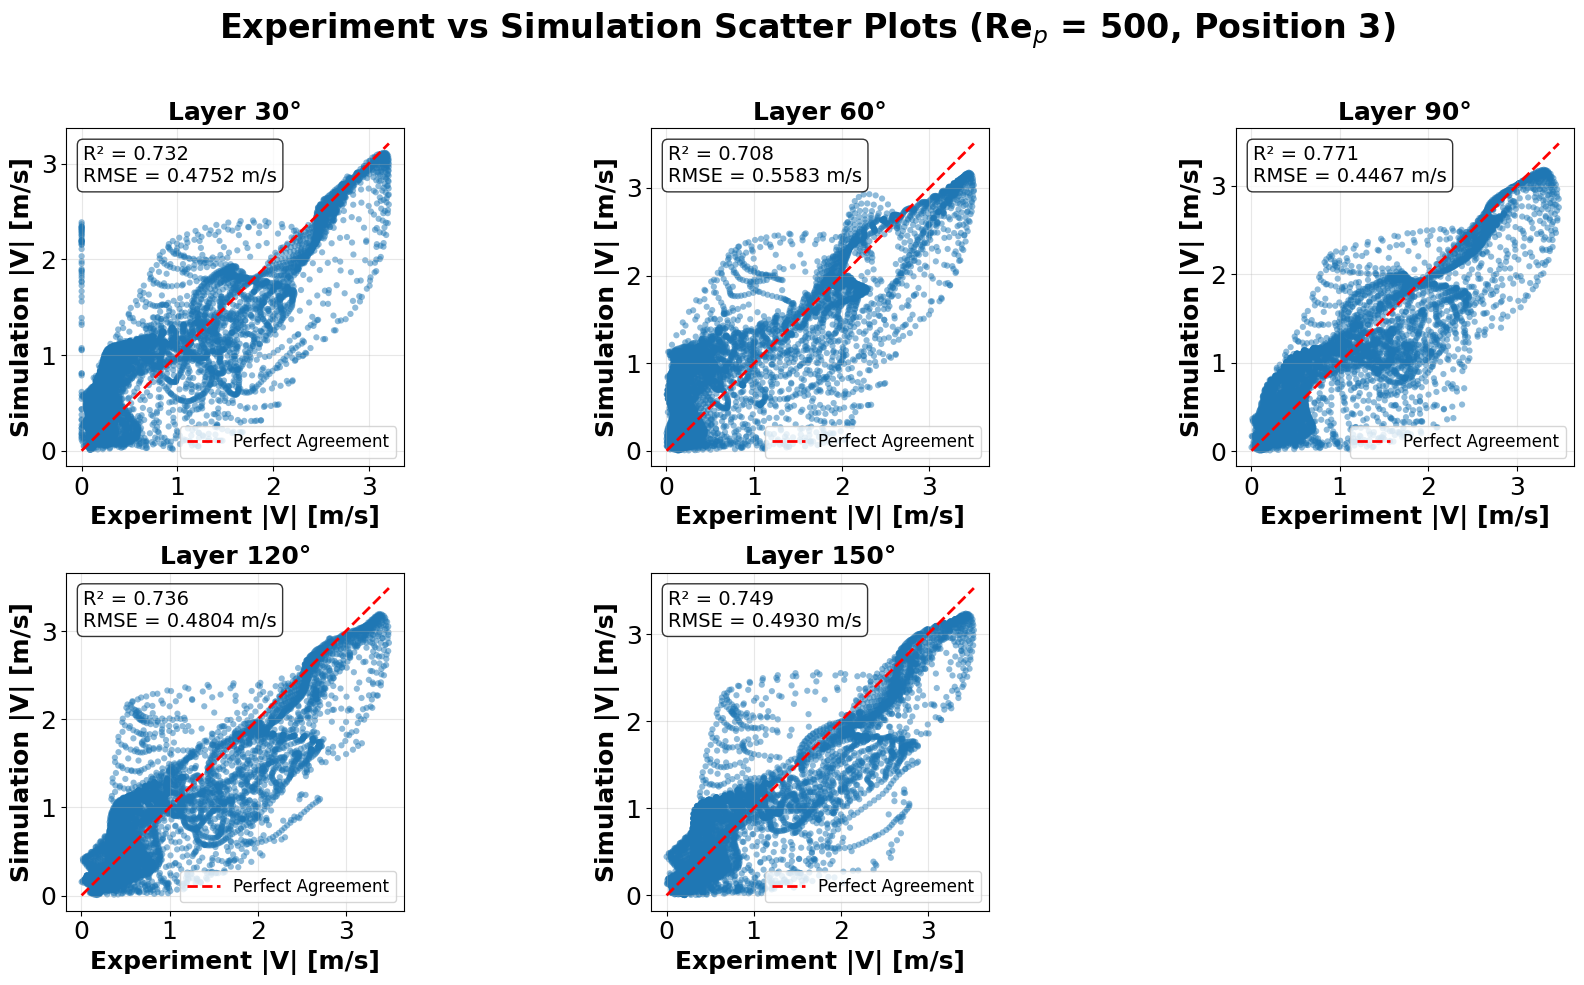

In [43]:
# Scatter plots: Experiment vs Simulation velocity comparison
print("\n" + "="*80)
print("CREATING SCATTER PLOTS (EXP VS SIM)")
print("="*80)

from scipy import stats

n_layers = min(len(exp_dataframes), len(sim_dataframes))

# Determine subplot layout
if n_layers <= 4:
    n_rows, n_cols = 2, 2
elif n_layers <= 6:
    n_rows, n_cols = 2, 3
else:
    n_rows, n_cols = 3, 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

# Process each layer
for i in range(n_layers):
    df_exp = exp_dataframes[i]
    df_sim = sim_dataframes[i]
    ax = axes[i]
    
    # Extract layer label
    exp_match = re.search(r'L(\d{2})', exp_file_names[i])
    layer_name = f"L{exp_match.group(1)}" if exp_match else f"Layer {i+1}"
    
    try:
        angle_deg = -np.degrees(df_exp['alpha'].iloc[0])
        layer_name = f"{angle_deg:.0f}°"
    except:
        pass
    
    # Interpolate simulation data to experimental grid for comparison
    from scipy.interpolate import griddata
    
    # Get experimental points
    x_exp = df_exp[exp_x_col].values
    z_exp = df_exp[exp_z_col].values
    vel_exp = df_exp['vel_magnitude'].values
    
    # Get simulation data
    x_sim = df_sim[sim_x_col].values
    z_sim = df_sim[sim_z_col].values
    vel_sim = df_sim['vel_magnitude'].values
    
    # Interpolate simulation to experimental points
    points_sim = np.column_stack((x_sim, z_sim))
    vel_sim_interp = griddata(points_sim, vel_sim, (x_exp, z_exp), method='linear')
    
    # Remove NaN values
    valid_mask = ~np.isnan(vel_sim_interp)
    vel_exp_valid = vel_exp[valid_mask]
    vel_sim_valid = vel_sim_interp[valid_mask]
    
    if len(vel_exp_valid) > 0:
        # Calculate statistics
        r_squared = np.corrcoef(vel_exp_valid, vel_sim_valid)[0, 1]**2
        rmse = np.sqrt(np.mean((vel_sim_valid - vel_exp_valid)**2))
        
        # Create scatter plot
        ax.scatter(vel_exp_valid, vel_sim_valid, alpha=0.5, s=20, edgecolors='none')
        
        # Add perfect agreement line (y=x)
        min_val = min(vel_exp_valid.min(), vel_sim_valid.min())
        max_val = max(vel_exp_valid.max(), vel_sim_valid.max())
        ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Agreement')
        
        # Add statistics text
        stats_text = f'R² = {r_squared:.3f}\nRMSE = {rmse:.4f} m/s'
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, 
               fontsize=14, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        ax.legend(fontsize=12, loc='lower right')
        
        # Equal aspect ratio for better visualization
        ax.set_aspect('equal', adjustable='box')
    
    # Configure subplot (always, regardless of data availability)
    ax.set_xlabel('Experiment |V| [m/s]', fontsize=18, fontweight='bold')
    ax.set_ylabel('Simulation |V| [m/s]', fontsize=18, fontweight='bold')
    ax.set_title(f'Layer {layer_name}', fontsize=18, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=18)

# Hide unused subplots
for i in range(n_layers, len(axes)):
    axes[i].set_visible(False)

fig.suptitle(f'Experiment vs Simulation Scatter Plots (Re$_p$ = {Re_p}, Position {position})', 
            fontsize=24, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save plot
scatter_filename = f'{output_dir}/Scatter_Exp_vs_Sim_Pos{position}_Re{Re_p}.png'
plt.savefig(scatter_filename, dpi=300, bbox_inches='tight')
print(f"\nSaved: {scatter_filename}")

plt.show()

print("="*80)


CREATING SPATIAL DIFFERENCE MAPS

Saved: ../Plots/Re500/Difference_Maps_Pos3_Re500.png


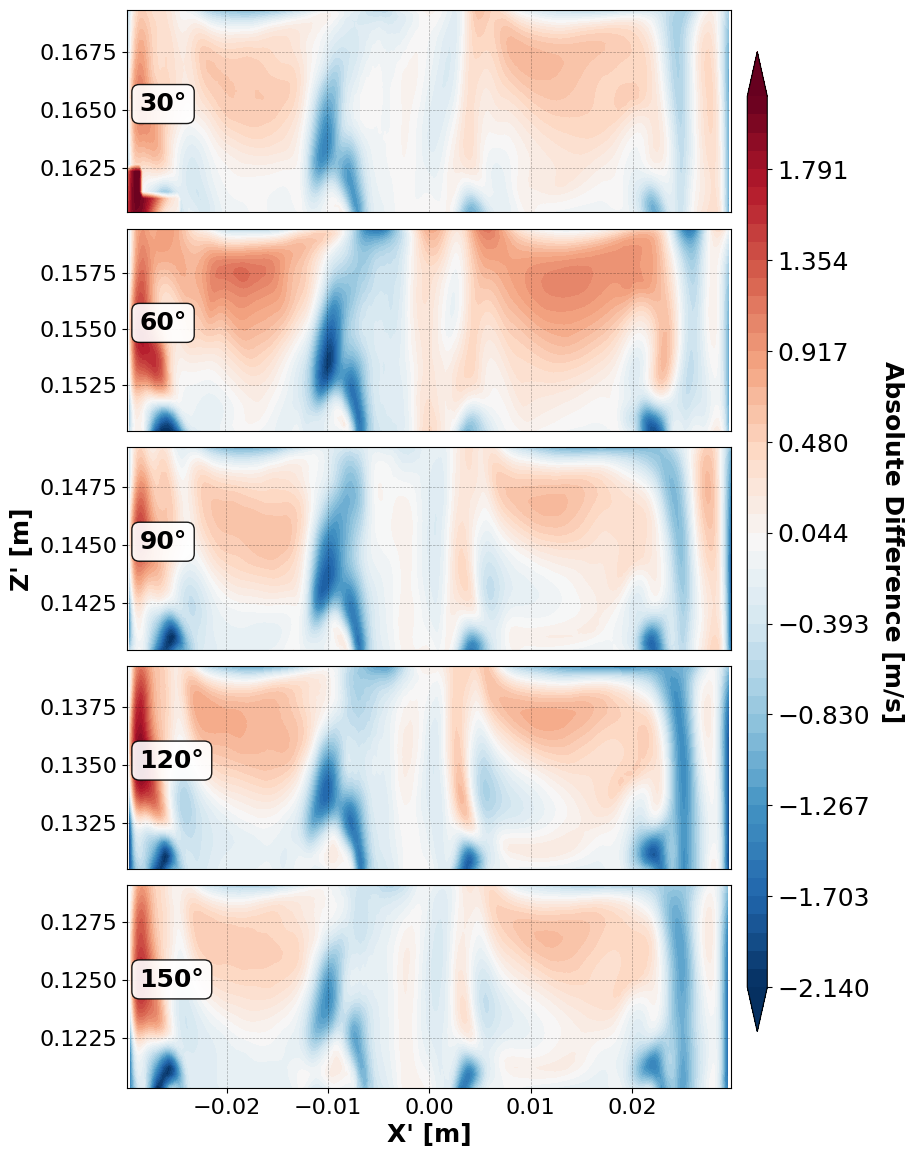

In [44]:
# Spatial difference maps: (Simulation - Experiment) -- absolute difference only
print("\n" + "="*80)
print("CREATING SPATIAL DIFFERENCE MAPS")
print("="*80)

n_layers = min(len(exp_dataframes), len(sim_dataframes))

# Create figure with a single column: Absolute Difference
fig, axes = plt.subplots(
    nrows=n_layers,
    ncols=1,
    figsize=(8, 2.8 * n_layers)
)

# Ensure axes is iterable (1D array indexed by layer)
if n_layers == 1:
    axes = np.array([axes])

# Process each layer
for i in range(n_layers):
    df_exp = exp_dataframes[i]
    df_sim = sim_dataframes[i]

    # Extract layer label
    exp_match = re.search(r'L(\d{2})', exp_file_names[i])
    layer_name = f"L{exp_match.group(1)}" if exp_match else f"Layer {i+1}"

    try:
        angle_deg = -np.degrees(df_exp['alpha'].iloc[0])
        layer_name = f"{angle_deg:.0f}°"
    except:
        pass

    # Create common grid for interpolation
    x_exp = df_exp[exp_x_col].values
    z_exp = df_exp[exp_z_col].values
    vel_exp = df_exp['vel_magnitude'].values

    x_sim = df_sim[sim_x_col].values
    z_sim = df_sim[sim_z_col].values
    vel_sim = df_sim['vel_magnitude'].values

    # Create grid based on experimental data extent
    xi = np.linspace(x_exp.min(), x_exp.max(), n_grid)
    zi = np.linspace(z_exp.min(), z_exp.max(), n_grid)
    Xi, Zi = np.meshgrid(xi, zi)

    # Interpolate both datasets to common grid
    points_exp = np.column_stack((x_exp, z_exp))
    points_sim = np.column_stack((x_sim, z_sim))

    Vel_exp_interp = griddata(points_exp, vel_exp, (Xi, Zi), method='linear')
    Vel_sim_interp = griddata(points_sim, vel_sim, (Xi, Zi), method='linear')

    # Calculate absolute difference
    Diff_abs = Vel_sim_interp - Vel_exp_interp  # Absolute difference

    # ========== ABSOLUTE DIFFERENCE ==========
    ax_abs = axes[i]

    # Calculate symmetric colorbar limits for diverging colormap
    abs_max = np.nanmax(np.abs(Diff_abs))
    abs_levels = np.linspace(-abs_max, abs_max, 50)

    contour_abs = ax_abs.contourf(Xi, Zi, Diff_abs, levels=abs_levels,
                                   cmap='RdBu_r', extend='both')

    ax_abs.set_xlim(x_exp.min(), x_exp.max())
    ax_abs.set_ylim(z_exp.min(), z_exp.max())
    ax_abs.grid(True, linestyle='--', alpha=0.3, color='black', linewidth=0.5)
    ax_abs.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    ax_abs.tick_params(axis='y', which='both', left=True, labelleft=True, labelsize=16)

    # Add layer label
    ax_abs.annotate(layer_name, xy=(0.02, 0.50), xycoords='axes fraction',
                    fontsize=18, fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.9))

# Show x-axis only on the bottom plot
axes[-1].tick_params(axis='x', which='both', bottom=True, labelbottom=True, labelsize=16)
axes[-1].set_xlabel("X' [m]", fontsize=18, fontweight='bold')

# Add y-axis label to the middle plot
middle_idx = n_layers // 2
axes[middle_idx].set_ylabel("Z' [m]", fontsize=18, fontweight='bold')

# Add colorbar for absolute difference
fig.subplots_adjust(right=0.88, hspace=0.08)
cbar_ax1 = fig.add_axes([0.90, 0.15, 0.025, 0.70])
cbar1 = fig.colorbar(contour_abs, cax=cbar_ax1)
cbar1.set_label('Absolute Difference [m/s]', rotation=270, labelpad=25, fontsize=18, fontweight='bold')
cbar1.ax.tick_params(labelsize=18)

# Save figure
diff_map_filename = f'{output_dir}/Difference_Maps_Pos{position}_Re{Re_p}.png'
plt.savefig(diff_map_filename, dpi=300, bbox_inches='tight')
print(f"\nSaved: {diff_map_filename}")

plt.show()

In [45]:
# Create mean velocity comparison table - both per-layer and combined
# Store per-layer comparisons
layer_comparisons = []

n_layers = min(len(exp_dataframes), len(sim_dataframes))

for i in range(n_layers):
    df_exp = exp_dataframes[i]
    df_sim = sim_dataframes[i]
    
    # Extract layer label
    exp_match = re.search(r'L(\d{2})', exp_file_names[i])
    layer_name = f"L{exp_match.group(1)}" if exp_match else f"Layer {i+1}"
    
    # Try to get angle from alpha column
    try:
        angle_deg = -np.degrees(df_exp['alpha'].iloc[0])
        layer_name = f"{angle_deg:.0f}°"
    except:
        pass
    
    # Get mean velocities for this layer
    exp_u_mean = df_exp[exp_u_col].mean()
    exp_w_mean = df_exp[exp_w_col].mean()
    exp_mag_mean = df_exp['vel_magnitude'].mean()
    
    sim_u_mean = df_sim[sim_u_col].mean()
    sim_w_mean = df_sim[sim_w_col].mean()
    sim_mag_mean = df_sim['vel_magnitude'].mean()
    
    # Store for each velocity component
    layer_comparisons.append({
        'Layer': layer_name,
        'Component': 'X-vel (u)',
        'Exp [m/s]': exp_u_mean,
        'Sim [m/s]': sim_u_mean,
        'Diff [m/s]': sim_u_mean - exp_u_mean,
        'Rel Diff [%]': ((sim_u_mean - exp_u_mean) / exp_u_mean) * 100 if exp_u_mean != 0 else 0
    })
    
    layer_comparisons.append({
        'Layer': layer_name,
        'Component': 'Z-vel (w)',
        'Exp [m/s]': exp_w_mean,
        'Sim [m/s]': sim_w_mean,
        'Diff [m/s]': sim_w_mean - exp_w_mean,
        'Rel Diff [%]': ((sim_w_mean - exp_w_mean) / exp_w_mean) * 100 if exp_w_mean != 0 else 0
    })
    
    layer_comparisons.append({
        'Layer': layer_name,
        'Component': 'Magnitude |V|',
        'Exp [m/s]': exp_mag_mean,
        'Sim [m/s]': sim_mag_mean,
        'Diff [m/s]': sim_mag_mean - exp_mag_mean,
        'Rel Diff [%]': ((sim_mag_mean - exp_mag_mean) / exp_mag_mean) * 100 if exp_mag_mean != 0 else 0
    })

# Create DataFrame for per-layer table
layer_comparison_df = pd.DataFrame(layer_comparisons)

# Format and display per-layer data
pd.options.display.float_format = '{:.6f}'.format
print("\n" + layer_comparison_df.to_string(index=False))

# Now create combined (all layers) comparison
print("\n" + "=" * 80)
print("MEAN VELOCITY COMPARISON - ALL LAYERS COMBINED")
print("=" * 80)

# Collect all velocity components from all layers
all_exp_u = []
all_exp_w = []
all_exp_mag = []
all_sim_u = []
all_sim_w = []
all_sim_mag = []

for df_exp in exp_dataframes:
    all_exp_u.extend(df_exp[exp_u_col].values)
    all_exp_w.extend(df_exp[exp_w_col].values)
    all_exp_mag.extend(df_exp['vel_magnitude'].values)

for df_sim in sim_dataframes:
    all_sim_u.extend(df_sim[sim_u_col].values)
    all_sim_w.extend(df_sim[sim_w_col].values)
    all_sim_mag.extend(df_sim['vel_magnitude'].values)

# Convert to arrays for calculation
all_exp_u = np.array(all_exp_u)
all_exp_w = np.array(all_exp_w)
all_exp_mag = np.array(all_exp_mag)
all_sim_u = np.array(all_sim_u)
all_sim_w = np.array(all_sim_w)
all_sim_mag = np.array(all_sim_mag)

# Create DataFrame for combined table
velocity_comparison = pd.DataFrame({
    #'Component': ['X-velocity (u)', 'Z-velocity (w)', 'Total magnitude |V|'],
    'Component': ['Total magnitude |V|'],
    'Experiment [m/s]': [
    #    all_exp_u.mean(),
    #    all_exp_w.mean(),
        all_exp_mag.mean()
    ],
    'Simulation [m/s]': [
    #    all_sim_u.mean(),
    #    all_sim_w.mean(),
        all_sim_mag.mean()
    ]
})

# Calculate differences and percentage
velocity_comparison['Difference [m/s]'] = (
    velocity_comparison['Simulation [m/s]'] - velocity_comparison['Experiment [m/s]']
)
velocity_comparison['Relative Diff [%]'] = (
    (velocity_comparison['Difference [m/s]'] / velocity_comparison['Experiment [m/s]']) * 100
)

# Format and display combined data
print("\n" + velocity_comparison.to_string(index=False))
print("\n" + "=" * 80 + "\n")

# Reset display format
pd.reset_option('display.float_format')


Layer     Component  Exp [m/s]  Sim [m/s]  Diff [m/s]  Rel Diff [%]
  30°     X-vel (u)  -0.152073  -0.292258   -0.140185     92.182746
  30°     Z-vel (w)   0.883980   0.818534   -0.065446     -7.403550
  30° Magnitude |V|   1.054161   1.101428    0.047266      4.483777
  60°     X-vel (u)   0.019820  -0.299917   -0.319737  -1613.165714
  60°     Z-vel (w)   0.858540   0.824726   -0.033814     -3.938588
  60° Magnitude |V|   0.993582   1.114708    0.121125     12.190759
  90°     X-vel (u)  -0.279109  -0.297520   -0.018411      6.596489
  90°     Z-vel (w)   0.962138   0.844143   -0.117994    -12.263759
  90° Magnitude |V|   1.205581   1.134691   -0.070891     -5.880201
 120°     X-vel (u)  -0.275593  -0.295486   -0.019893      7.218310
 120°     Z-vel (w)   0.965103   0.832489   -0.132614    -13.740926
 120° Magnitude |V|   1.204757   1.119679   -0.085078     -7.061813
 150°     X-vel (u)  -0.236427  -0.293354   -0.056928     24.078320
 150°     Z-vel (w)   1.004824   0.833526   -0.


SUMMARY: Mean Velocity Magnitude Per Layer

Layer  Mean_Vel_Exp_m/s  Mean_Vel_Sim_m/s  Difference_m/s  Rel_Diff_%
  30°          1.054161          1.101428        0.047266    4.483777
  60°          0.993582          1.114708        0.121125   12.190759
  90°          1.205581          1.134691       -0.070891   -5.880201
 120°          1.204757          1.119679       -0.085078   -7.061813
 150°          1.211442          1.123855       -0.087586   -7.229928

Average Difference (Sim - Exp) [m/s]: -0.015033
Average Absolute Difference [m/s]: 0.082389
Average Relative Difference [%]: -0.699

Summary saved to: ../Plots/Re500/Layer_Velocity_Summary_Pos3_Re500.csv


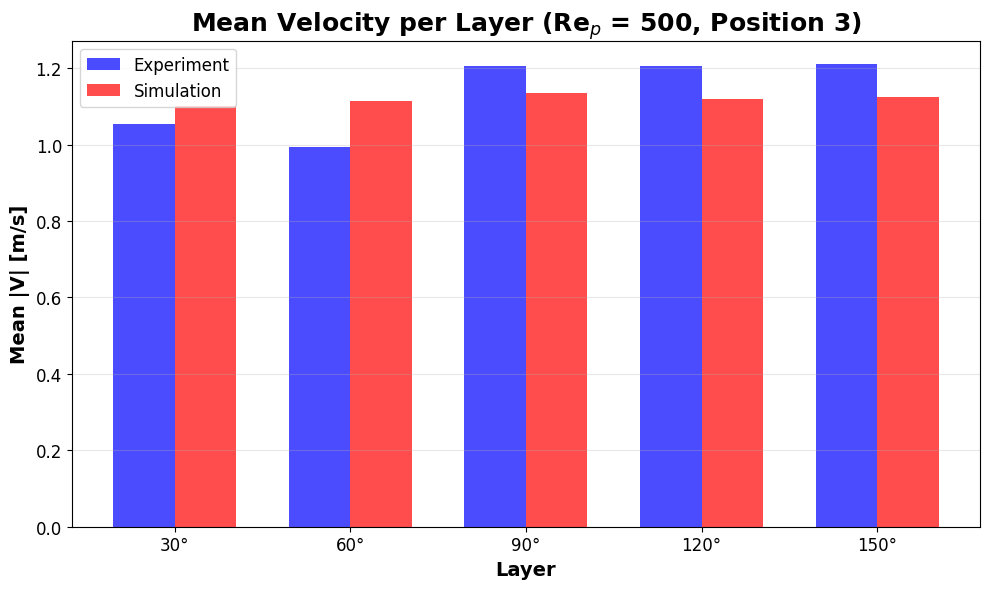

In [46]:
# Create summary DataFrame showing mean velocities per layer
print("\n" + "="*80)
print("SUMMARY: Mean Velocity Magnitude Per Layer")
print("="*80)

layer_names = []
layer_mean_vel_exp = []
layer_mean_vel_sim = []

n_layers = min(len(exp_dataframes), len(sim_dataframes))

for i in range(n_layers):
    df_exp = exp_dataframes[i]
    df_sim = sim_dataframes[i]
    
    # Extract layer label
    exp_match = re.search(r'L(\d{2})', exp_file_names[i])
    layer_name = f"L{exp_match.group(1)}" if exp_match else f"Layer {i+1}"
    
    # Try to get angle from alpha column
    try:
        angle_deg = -np.degrees(df_exp['alpha'].iloc[0])
        layer_name = f"{angle_deg:.0f}°"
    except:
        pass
    
    layer_names.append(layer_name)
    layer_mean_vel_exp.append(df_exp['vel_magnitude'].mean())
    layer_mean_vel_sim.append(df_sim['vel_magnitude'].mean())

# Create summary DataFrame
summary_df = pd.DataFrame({
    'Layer': layer_names,
    'Mean_Vel_Exp_m/s': layer_mean_vel_exp,
    'Mean_Vel_Sim_m/s': layer_mean_vel_sim,
    'Difference_m/s': np.array(layer_mean_vel_sim) - np.array(layer_mean_vel_exp),
    'Rel_Diff_%': ((np.array(layer_mean_vel_sim) - np.array(layer_mean_vel_exp)) / np.array(layer_mean_vel_exp)) * 100
})

# Format and display
pd.options.display.float_format = '{:.6f}'.format
print("\n" + summary_df.to_string(index=False))

# Calculate averages
avg_diff = summary_df['Difference_m/s'].mean()
avg_abs_diff = summary_df['Difference_m/s'].abs().mean()
avg_rel_diff = summary_df['Rel_Diff_%'].mean()

print(f"\nAverage Difference (Sim - Exp) [m/s]: {avg_diff:.6f}")
print(f"Average Absolute Difference [m/s]: {avg_abs_diff:.6f}")
print(f"Average Relative Difference [%]: {avg_rel_diff:.3f}")
print("="*80 + "\n")

# Reset display format
pd.reset_option('display.float_format')

# Create plot showing mean velocity per layer
fig, ax = plt.subplots(figsize=(10, 6))
x_positions = np.arange(len(layer_names))
width = 0.35

ax.bar(x_positions - width/2, layer_mean_vel_exp, width, label='Experiment', color='b', alpha=0.7)
ax.bar(x_positions + width/2, layer_mean_vel_sim, width, label='Simulation', color='r', alpha=0.7)

ax.set_xlabel('Layer', fontsize=14, fontweight='bold')
ax.set_ylabel('Mean |V| [m/s]', fontsize=14, fontweight='bold')
ax.set_title(f'Mean Velocity per Layer (Re$_p$ = {Re_p}, Position {position})', fontsize=18, fontweight='bold')
ax.set_xticks(x_positions)
ax.set_xticklabels(layer_names)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
ax.tick_params(labelsize=12)
plt.tight_layout()

# Save summary
summary_filename = f'{output_dir}/Layer_Velocity_Summary_Pos{position}_Re{Re_p}.csv'
summary_df.to_csv(summary_filename, index=False)
print(f"Summary saved to: {summary_filename}")

# Save plot
#plot_filename = f'{output_dir}/Mean_Velocity_per_Layer_Bar_Pos{position}_Re{Re_p}.png'
#plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
#print(f"Plot saved to: {plot_filename}")

#plt.show()


SUMMARY: Mean Velocity Magnitude Per Layer

Layer  Mean_Vel_Exp_m/s  Mean_Vel_Sim_m/s  Difference_m/s  Rel_Diff_%
  30°          1.054161          1.101428        0.047266    4.483777
  60°          0.993582          1.114708        0.121125   12.190759
  90°          1.205581          1.134691       -0.070891   -5.880201
 120°          1.204757          1.119679       -0.085078   -7.061813
 150°          1.211442          1.123855       -0.087586   -7.229928

Average Difference (Sim - Exp) [m/s]: -0.015033
Average Absolute Difference [m/s]: 0.082389
Average Relative Difference [%]: -0.699

Summary saved to: ../Plots/Re500/Layer_Velocity_Summary_Pos3_Re500.csv
Plot saved to: ../Plots/Re500/Mean_Velocity_per_Layer_Pos3_Re500.png


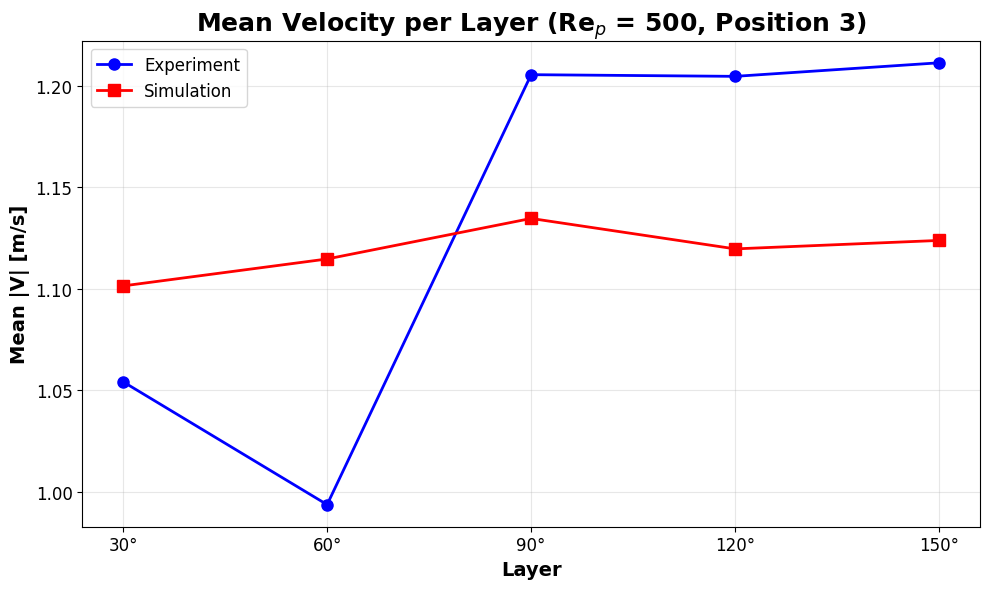

In [47]:
# Create summary DataFrame showing mean velocities per layer
print("\n" + "="*80)
print("SUMMARY: Mean Velocity Magnitude Per Layer")
print("="*80)

layer_names = []
layer_mean_vel_exp = []
layer_mean_vel_sim = []

n_layers = min(len(exp_dataframes), len(sim_dataframes))

for i in range(n_layers):
    df_exp = exp_dataframes[i]
    df_sim = sim_dataframes[i]
    
    # Extract layer label
    exp_match = re.search(r'L(\d{2})', exp_file_names[i])
    layer_name = f"L{exp_match.group(1)}" if exp_match else f"Layer {i+1}"
    
    # Try to get angle from alpha column
    try:
        angle_deg = -np.degrees(df_exp['alpha'].iloc[0])
        layer_name = f"{angle_deg:.0f}°"
    except:
        pass
    
    layer_names.append(layer_name)
    layer_mean_vel_exp.append(df_exp['vel_magnitude'].mean())
    layer_mean_vel_sim.append(df_sim['vel_magnitude'].mean())

# Create summary DataFrame
summary_df = pd.DataFrame({
    'Layer': layer_names,
    'Mean_Vel_Exp_m/s': layer_mean_vel_exp,
    'Mean_Vel_Sim_m/s': layer_mean_vel_sim,
    'Difference_m/s': np.array(layer_mean_vel_sim) - np.array(layer_mean_vel_exp),
    'Rel_Diff_%': ((np.array(layer_mean_vel_sim) - np.array(layer_mean_vel_exp)) / np.array(layer_mean_vel_exp)) * 100
})

# Format and display
pd.options.display.float_format = '{:.6f}'.format
print("\n" + summary_df.to_string(index=False))

# Calculate averages
avg_diff = summary_df['Difference_m/s'].mean()
avg_abs_diff = summary_df['Difference_m/s'].abs().mean()
avg_rel_diff = summary_df['Rel_Diff_%'].mean()

print(f"\nAverage Difference (Sim - Exp) [m/s]: {avg_diff:.6f}")
print(f"Average Absolute Difference [m/s]: {avg_abs_diff:.6f}")
print(f"Average Relative Difference [%]: {avg_rel_diff:.3f}")
print("="*80 + "\n")

# Reset display format
pd.reset_option('display.float_format')

# Create line plot showing mean velocity per layer
fig, ax = plt.subplots(figsize=(10, 6))
x_positions = np.arange(len(layer_names))

ax.plot(x_positions, layer_mean_vel_exp, 'bo-', label='Experiment', linewidth=2, markersize=8)
ax.plot(x_positions, layer_mean_vel_sim, 'rs-', label='Simulation', linewidth=2, markersize=8)

ax.set_xlabel('Layer', fontsize=14, fontweight='bold')
ax.set_ylabel('Mean |V| [m/s]', fontsize=14, fontweight='bold')
ax.set_title(f'Mean Velocity per Layer (Re$_p$ = {Re_p}, Position {position})', fontsize=18, fontweight='bold')
ax.set_xticks(x_positions)
ax.set_xticklabels(layer_names)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
ax.tick_params(labelsize=12)
plt.tight_layout()

# Save summary
summary_filename = f'{output_dir}/Layer_Velocity_Summary_Pos{position}_Re{Re_p}.csv'
summary_df.to_csv(summary_filename, index=False)
print(f"Summary saved to: {summary_filename}")

# Save plot
plot_filename = f'{output_dir}/Mean_Velocity_per_Layer_Pos{position}_Re{Re_p}.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"Plot saved to: {plot_filename}")

plt.show()

In [48]:
# SYMMETRY CHECK: Compare same layers from 2 different folders
symmetry_distance = 0.002  # Distance from bottom in meters (2 mm)

# Define the two folders to compare
folder1_path = '../30/sim/30_Re_100/Pos3_transformed'
folder2_path = '../30/sim/30_Re_100/Pos5_transformed'
label1 = 'Pos 3'
label2 = 'Pos 5 (flipped)'

FLIP_LAYERS = 0
TRIM_TO_COMMON_X_RANGE = 1

In [49]:
# # Column mappings (using simulation data for symmetry check)
# sym_x_col = 'Points_0'
# sym_z_col = 'Points_2'
# sym_u_col = 'av_u_0'
# sym_w_col = 'av_u_2'

# # Load files from both folders
# folder1_files = sorted(glob.glob(f"{folder1_path}/*.csv"))[::-1]  # Reverse for layer order
# folder2_files = sorted(glob.glob(f"{folder2_path}/*.csv"))[::-1]

# print(f"\nFolder 1: {folder1_path}")
# print(f"  Found {len(folder1_files)} files")
# print(f"\nFolder 2: {folder2_path}")
# print(f"  Found {len(folder2_files)} files")

# # Load dataframes
# folder1_dfs = [pd.read_csv(file) for file in folder1_files]
# folder2_dfs = [pd.read_csv(file) for file in folder2_files]

# # Extract file names
# folder1_names = [os.path.basename(file) for file in folder1_files]
# folder2_names = [os.path.basename(file) for file in folder2_files]

# # Match layers by layer number (L12, L13, etc.)
# layer_pairs = []
# for i, name1 in enumerate(folder1_names):
#     layer1_match = re.search(r'(L\d{2})', name1)
#     if layer1_match:
#         layer1_num = layer1_match.group(1)
        
#         # Find matching layer in folder 2
#         for j, name2 in enumerate(folder2_names):
#             layer2_match = re.search(r'(L\d{2})', name2)
#             if layer2_match and layer2_match.group(1) == layer1_num:
#                 layer_pairs.append({
#                     'layer_num': layer1_num,
#                     'folder1_idx': i,
#                     'folder2_idx': j,
#                     'folder1_name': name1,
#                     'folder2_name': name2
#                 })
#                 break

# #print(f"\nMatched {len(layer_pairs)} layer pairs")
# for pair in layer_pairs:
#     print(f"  {pair['layer_num']}: {pair['folder1_name']} vs {pair['folder2_name']}")

# # Determine subplot layout
# n_pairs = len(layer_pairs)
# if n_pairs <= 4:
#     n_rows, n_cols = 2, 2
# elif n_pairs <= 6:
#     n_rows, n_cols = 2, 3
# elif n_pairs <= 9:
#     n_rows, n_cols = 3, 3
# else:
#     n_rows, n_cols = 4, 3

# # Create figure with subplots
# fig, axes = plt.subplots(n_rows, n_cols, figsize=(7*n_cols, 5*n_rows))
# axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

# deci = 5  # Precision for filtering

# # Process each layer pair
# for pair_idx, pair in enumerate(layer_pairs):
#     ax = axes[pair_idx]
    
#     # Get both layers
#     df_folder1 = folder1_dfs[pair['folder1_idx']].copy()
#     df_folder2 = folder2_dfs[pair['folder2_idx']].copy()
    
#     # Calculate velocity magnitude for both
#     df_folder1['vel_magnitude'] = np.sqrt(df_folder1[sym_u_col]**2 + df_folder1[sym_w_col]**2)
#     df_folder2['vel_magnitude'] = np.sqrt(df_folder2[sym_u_col]**2 + df_folder2[sym_w_col]**2)
    
#     # Flip folder 2 horizontally (mirror across X-axis)
#     x_center = (df_folder2[sym_x_col].max() + df_folder2[sym_x_col].min()) / 2
#     df_folder2[sym_x_col] = 2 * x_center - df_folder2[sym_x_col]
#     df_folder2[sym_u_col] = -df_folder2[sym_u_col]  # Flip X-velocity component
#     # Recalculate velocity magnitude
#     df_folder2['vel_magnitude'] = np.sqrt(df_folder2[sym_u_col]**2 + df_folder2[sym_w_col]**2)
    
#     # Extract position numbers for labels
#     pos1_match = re.search(r'Pos(\d+)', pair['folder1_name'])
#     pos2_match = re.search(r'Pos(\d+)', pair['folder2_name'])
#     pos1 = pos1_match.group(1) if pos1_match else '1'
#     pos2 = pos2_match.group(1) if pos2_match else '2'
    
#  #   print(f"\nPair {pair_idx+1}: {pair['layer_num']} - Pos{pos1} vs Pos{pos2} (flipped)")
    
#     # Calculate z-position for folder 1 (distance from its bottom)
#     z_min_folder1 = df_folder1[sym_z_col].min()
#     z_target_folder1 = z_min_folder1 + symmetry_distance
    
#     # Calculate z-position for folder 2 (distance from its bottom)
#     z_min_folder2 = df_folder2[sym_z_col].min()
#     z_target_folder2 = z_min_folder2 + symmetry_distance
    
#     # Check if this distance exists in both layers
#     folder1_exists = z_target_folder1 <= df_folder1[sym_z_col].max()
#     folder2_exists = z_target_folder2 <= df_folder2[sym_z_col].max()
    
#     if folder1_exists and folder2_exists:
#         # FOLDER 1
#         closest_z_folder1 = df_folder1[sym_z_col].iloc[(df_folder1[sym_z_col] - z_target_folder1).abs().argsort()[:1]].iloc[0]
#         df_folder1_filtered = df_folder1[abs(df_folder1[sym_z_col] - closest_z_folder1) < 10**(-deci)]
        
#         if len(df_folder1_filtered) > 0:
#             df_folder1_filtered = df_folder1_filtered.sort_values(sym_x_col)
            
#             # Plot folder 1
#             ax.plot(df_folder1_filtered[sym_x_col], df_folder1_filtered['vel_magnitude'], 
#                    label=label1, color='b', linestyle='-', linewidth=2.5, zorder=2)
        
#         # FOLDER 2 (FLIPPED)
#         closest_z_folder2 = df_folder2[sym_z_col].iloc[(df_folder2[sym_z_col] - z_target_folder2).abs().argsort()[:1]].iloc[0]
#         df_folder2_filtered = df_folder2[abs(df_folder2[sym_z_col] - closest_z_folder2) < 10**(-deci)]
        
#         if len(df_folder2_filtered) > 0:
#             df_folder2_filtered = df_folder2_filtered.sort_values(sym_x_col)
            
#             # Plot folder 2 (flipped)
#             ax.plot(df_folder2_filtered[sym_x_col], df_folder2_filtered['vel_magnitude'], 
#                    label=label2, color='r', linestyle='--', linewidth=2.5, zorder=3, alpha=0.8)
        
#         # Calculate statistics if both have data
#         if len(df_folder1_filtered) > 0 and len(df_folder2_filtered) > 0:
#             # Interpolate to compare at same X positions
#             from scipy.interpolate import interp1d
            
#             x_common = np.linspace(
#                 max(df_folder1_filtered[sym_x_col].min(), df_folder2_filtered[sym_x_col].min()),
#                 min(df_folder1_filtered[sym_x_col].max(), df_folder2_filtered[sym_x_col].max()),
#                 100
#             )
            
#             if len(df_folder1_filtered[sym_x_col]) > 1 and len(df_folder2_filtered[sym_x_col]) > 1:
#                 f_folder1 = interp1d(df_folder1_filtered[sym_x_col], df_folder1_filtered['vel_magnitude'], 
#                                    kind='linear', bounds_error=False, fill_value=np.nan)
#                 f_folder2 = interp1d(df_folder2_filtered[sym_x_col], df_folder2_filtered['vel_magnitude'], 
#                                    kind='linear', bounds_error=False, fill_value=np.nan)
                
#                 vel_folder1_interp = f_folder1(x_common)
#                 vel_folder2_interp = f_folder2(x_common)
                
#                 # Remove NaN values
#                 valid_mask = ~(np.isnan(vel_folder1_interp) | np.isnan(vel_folder2_interp))
                
#                 if np.sum(valid_mask) > 1:
#                     vel_folder1_valid = vel_folder1_interp[valid_mask]
#                     vel_folder2_valid = vel_folder2_interp[valid_mask]
                    
#                     # Calculate statistics
#                     rmse = np.sqrt(np.mean((vel_folder2_valid - vel_folder1_valid)**2))
#                     mean_diff = np.mean(vel_folder2_valid - vel_folder1_valid)
                    
#                     # # Add statistics text
#                     # stats_text = f'RMSE = {rmse:.4f} m/s\nMean Diff = {mean_diff:.4f} m/s'
#                     # ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, 
#                     #        fontsize=12, verticalalignment='top',
#                     #        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
#     # Configure subplot
#     ax.set_xlabel('X [m]', fontsize=18, fontweight='bold')
#     ax.set_ylabel('|V| [m/s]', fontsize=18, fontweight='bold')
#     ax.set_title(f'{pair["layer_num"]}', fontsize=18, fontweight='bold')
#     ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.8)
#     ax.tick_params(axis='x', which='both', labelsize=18)
#     ax.tick_params(axis='y', which='both', labelsize=18)

# # Add legend only to the last pair
# if n_pairs > 0:
#     axes[n_pairs - 1].legend(fontsize=18, loc='best', frameon=True)

# # Hide unused subplots
# for i in range(n_pairs, len(axes)):
#     axes[i].set_visible(False)

# # Add overall title
# #fig.suptitle(f'Symmetry Check: Pos{pos1} vs Pos{pos2} (flipped) at {symmetry_distance*1000:.1f} mm from Bottom', 
# #            fontsize=18, fontweight='bold', y=0.995)

# # Adjust layout
# plt.tight_layout(rect=[0, 0, 1, 0.98])

# # Save plot
# #plot_filename = f'{output_dir}/Symmetry_Check_Pos_flipped_{symmetry_distance*1000:.0f}mm.png'
# #plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
# print(f"\nSaved: {plot_filename}")

# plt.show()